# Macaque cortical responses to white noise in V1
The six panels compare simulated and theoretical measures for 29 excitatory populations. The source is the first excitatory population. The cross-covariance lag sign follows NewNoiseLoad.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
from theory import auto_theory_from_OU, cross_cov_theory_two_methods

with np.load("results/primate_noise.npz") as data:
    H = data["H"]
    q00 = float(data["q00"])
    metrics = {key: data[key] for key in data.files if key not in ("H", "q00")}
N = len(H)
Path("figures").mkdir(exist_ok=True)

## Autocovariance

In [2]:
tau_list, peak_list, amp_list, P_inf = auto_theory_from_OU(H, q00)

In [3]:
bwith = 2

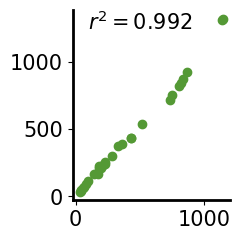

In [4]:
plt.figure(figsize = (2.5 ,2.5))
ax = plt.gca()
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.spines['bottom'].set_linewidth(bwith)
ax.spines['left'].set_linewidth(bwith)
exc_N = int(N / 2)
plt.scatter(tau_list[:exc_N], metrics['auto_tau'][:exc_N], color= '#549935')
x = np.asarray(tau_list[:exc_N], dtype=float).reshape(-1)
y = np.asarray(metrics['auto_tau'][:exc_N], dtype=float).reshape(-1)
A = np.column_stack([x, np.ones_like(x)])     
a, b = np.linalg.lstsq(A, y, rcond=None)[0]
predicts = a * x + b
ss_res = np.sum((y - predicts) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
R2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
R2 = round(float(R2), 4)
ax.text(0.1, 0.9, r"$r^2=$" + str(R2), transform=ax.transAxes, fontdict={'size': 15, 'color': 'black'})
ax.tick_params(axis='both', which='major', labelsize=15)
plt.tight_layout()
plt.savefig('figures/AutoWeak_time.pdf', dpi =300)
plt.show()

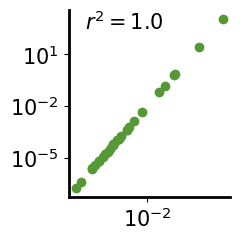

In [5]:
plt.figure(figsize=(2.5, 2.5))
ax = plt.gca()
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.spines['bottom'].set_linewidth(bwith)
ax.spines['left'].set_linewidth(bwith)
x = np.array(np.array(amp_list[:exc_N]), dtype=float)
y = np.array(metrics['auto_area'][:exc_N], dtype=float)
ax.scatter(x, y, color= '#549935')
ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax.xaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
ax.yaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
subs = np.arange(2, 10) * 0.1
ax.xaxis.set_minor_locator(mticker.LogLocator(base=10.0, subs=subs))
ax.yaxis.set_minor_locator(mticker.LogLocator(base=10.0, subs=subs))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.tick_params(axis='both', which='major', labelsize=15)
ax.tick_params(axis='both', which='minor', length=2)
x = np.asarray(np.array(amp_list[:exc_N]), dtype=float).reshape(-1)
y = np.asarray(metrics['auto_area'][:exc_N], dtype=float).reshape(-1)
A = np.column_stack([x, np.ones_like(x)])     
a, b = np.linalg.lstsq(A, y, rcond=None)[0]
predicts = a * x + b
ss_res = np.sum((y - predicts) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
R2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
R2 = round(float(R2), 4)
ax.text(0.1, 0.9, rf"$r^2={R2}$", transform=ax.transAxes, fontsize=15, color='black')
plt.tight_layout()
plt.savefig('figures/AutoWeak_amp.pdf', dpi =300)
plt.show()

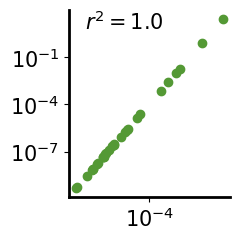

In [6]:
plt.figure(figsize=(2.5, 2.5))
ax = plt.gca()
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.spines['bottom'].set_linewidth(bwith)
ax.spines['left'].set_linewidth(bwith)
x = np.array(np.array(peak_list[:exc_N]), dtype=float)
y = np.array(metrics['auto_peak'][:exc_N], dtype=float)
ax.scatter(x, y, color= '#549935')
ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax.xaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
ax.yaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
subs = np.arange(2, 10) * 0.1
ax.xaxis.set_minor_locator(mticker.LogLocator(base=10.0, subs=subs))
ax.yaxis.set_minor_locator(mticker.LogLocator(base=10.0, subs=subs))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.tick_params(axis='both', which='major', labelsize=15)
ax.tick_params(axis='both', which='minor', length=2)
x = np.asarray(np.array(peak_list[:exc_N]), dtype=float).reshape(-1)
y = np.asarray(metrics['auto_peak'][:exc_N], dtype=float).reshape(-1)
A = np.column_stack([x, np.ones_like(x)])     
a, b = np.linalg.lstsq(A, y, rcond=None)[0]
predicts = a * x + b
ss_res = np.sum((y - predicts) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
R2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
R2 = round(float(R2), 4)
ax.text(0.1, 0.9, rf"$r^2={R2}$", transform=ax.transAxes, fontsize=15, color='black')
plt.tight_layout()
plt.savefig('figures/AutoWeak_peak.pdf', dpi =300)
plt.show()

## Cross-covariance

In [7]:
out_cross = cross_cov_theory_two_methods(H, m=0, q00=q00)

thr_amp_lyap = out_cross["lyap"]["amp"]
thr_t_lyap   = out_cross["lyap"]["t_peak"]
thr_peak_lyap= out_cross["lyap"]["peak"]
thr_amp_eig  = out_cross["eig"]["amp"]
thr_t_eig    = out_cross["eig"]["t_peak"]
thr_peak_eig = out_cross["eig"]["peak"]
thr_t_low = out_cross["low"]["t_peak"]

/home/xiaogebao/Propagation-Network/PrimateCortex/theory.py:98: ComplexWarning: Casting complex values to real discards the imaginary part
  tau_theory_list[area_idx] = -tau_num / tau_dom


In [8]:
bwith = 2

[-5.20756304e-16 -1.21222936e+01 -1.93334417e+00  2.43448196e+01
  2.61888807e+01  2.26376202e+02  2.93746278e+02  8.33616877e+01
  5.63767709e+01  3.27267447e+02  7.01647107e+02  2.83935350e+02
  1.28065053e+02  2.37525487e+02  4.18838782e+02  4.14234215e+02
  2.53450234e+02  2.30636422e+02  1.53229716e+02  7.85661326e+02
  1.81101176e+02  2.87857952e+02  7.58267726e+02  7.18853841e+02
  4.56675525e+02  7.99559696e+02  7.59072517e+02  1.04805420e+03
  1.03923786e+03] [ -0.   1.   3.   5.   3.   8.  13.   5.   5.   9. 143.   5.   8.   5.
  11.  13.   5.   3.   8.  12.   6.  12. 188.  14. 119.   9. 248. 448.
 446.]


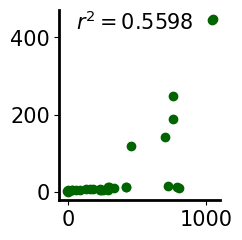

In [9]:
plt.figure(figsize = (2.5, 2.5))
ax = plt.gca()
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.spines['bottom'].set_linewidth(bwith)
ax.spines['left'].set_linewidth(bwith)
exc_N = int(N / 2)
plt.scatter(thr_t_eig[:exc_N], -metrics['cross_t_peak'][:exc_N], color= 'darkgreen')
x = np.asarray(thr_t_eig[:exc_N], dtype=float).reshape(-1)
y = np.asarray(-metrics['cross_t_peak'][:exc_N], dtype=float).reshape(-1)
print(x, y)
A = np.column_stack([x, np.ones_like(x)])     
a, b = np.linalg.lstsq(A, y, rcond=None)[0]
predicts = a * x + b
ss_res = np.sum((y - predicts) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
R2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
R2 = round(float(R2), 4)
ax.text(0.1, 0.9, r"$r^2=$" + str(R2), transform=ax.transAxes, fontdict={'size': 15, 'color': 'black'})
ax.tick_params(axis='both', which='major', labelsize=15)
plt.tight_layout()
plt.savefig('figures/CrossWeak_time.pdf', dpi =300)
plt.show()

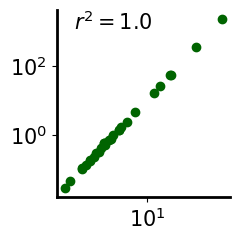

In [10]:
plt.figure(figsize=(2.5, 2.5))
ax = plt.gca()
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.spines['bottom'].set_linewidth(bwith)
ax.spines['left'].set_linewidth(bwith)
x = np.array(np.array(thr_amp_eig[:exc_N]), dtype=float)
y = np.array(metrics['cross_area'][:exc_N], dtype=float)
ax.scatter(x, y, color= 'darkgreen')
ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax.xaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
ax.yaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
subs = np.arange(2, 10) * 0.1
ax.xaxis.set_minor_locator(mticker.LogLocator(base=10.0, subs=subs))
ax.yaxis.set_minor_locator(mticker.LogLocator(base=10.0, subs=subs))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.tick_params(axis='both', which='major', labelsize=15)
ax.tick_params(axis='both', which='minor', length=2)
x = np.asarray(thr_amp_eig[:exc_N], dtype=float).reshape(-1)
y = np.asarray(metrics['cross_area'][:exc_N], dtype=float).reshape(-1)
A = np.column_stack([x, np.ones_like(x)])     
a, b = np.linalg.lstsq(A, y, rcond=None)[0]
predicts = a * x + b
ss_res = np.sum((y - predicts) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
R2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
R2 = round(float(R2), 4)
ax.text(0.1, 0.9, rf"$r^2={R2}$", transform=ax.transAxes, fontsize=15, color='black')
plt.tight_layout()
plt.savefig('figures/CrossWeak_amp.pdf', dpi =300)
plt.show()

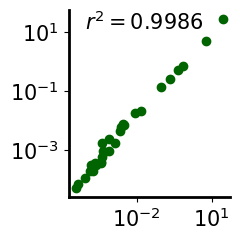

In [11]:
plt.figure(figsize=(2.5, 2.5))
ax = plt.gca()
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')
ax.spines['bottom'].set_linewidth(bwith)
ax.spines['left'].set_linewidth(bwith)
x = np.array(np.array(thr_peak_eig[:exc_N]), dtype=float)
y = np.array(metrics['cross_peak'][:exc_N], dtype=float)
ax.scatter(x, y, color= 'darkgreen')
ax.set_xscale('log')
ax.set_yscale('log')
ax.xaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax.yaxis.set_major_locator(mticker.LogLocator(base=10.0))
ax.xaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
ax.yaxis.set_major_formatter(mticker.LogFormatterMathtext(base=10.0))
subs = np.arange(2, 10) * 0.1
ax.xaxis.set_minor_locator(mticker.LogLocator(base=10.0, subs=subs))
ax.yaxis.set_minor_locator(mticker.LogLocator(base=10.0, subs=subs))
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.tick_params(axis='both', which='major', labelsize=15)
ax.tick_params(axis='both', which='minor', length=2)
x = np.asarray(np.array(thr_peak_eig[:exc_N]), dtype=float).reshape(-1)
y = np.asarray(metrics['cross_peak'][:exc_N], dtype=float).reshape(-1)
A = np.column_stack([x, np.ones_like(x)])     
a, b = np.linalg.lstsq(A, y, rcond=None)[0]
predicts = a * x + b
ss_res = np.sum((y - predicts) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
R2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
R2 = round(float(R2), 4)
ax.text(0.1, 0.9, rf"$r^2={R2}$", transform=ax.transAxes, fontsize=15, color='black')
plt.tight_layout()
plt.savefig('figures/CrossWeak_peak.pdf', dpi =300)
plt.show()